# Held-out: does NIQE vector + T3 beat Ramen on ImageNet-R / -A / -Sketch?

**Question.** On ImageNet-C, stacking the whitened NIQE-vector selection term (λ = 0.1) on RamenActive's zero-shot class weighting (T = 3) gave +0.87 ± 0.10 over Ramen, every seed above the floor (`../2026-11-20_nss_t3_stack/`). Both settings were chosen on ImageNet-C. Does the stack hold on a stream whose domains are renditions, adversarially filtered photos and sketches rather than pixel-level corruptions?

**Hypothesis (pre-registered, `PREREGISTRATION.md`, written before any NIQE run on this data).** Primary: mean gain of NIQE + T3 over Ramen > the noise floor. Secondary: NIQE + T3 beats T3 alone on the mean and on ≥ 4 of 5 seeds. Written-down alternative: if NIQE only helps because ImageNet-C's domains are corruptions, NIQE alone ≈ 0 here and the stack ≈ T3.

**Runs** (true labels used only for scoring):

| Name here | Cached run | What it changes vs Ramen | Run in this experiment? |
|---|---|---|---|
| Ramen | `Ramen` | — (baseline) | no, cached (`../2026-10-25_heldout/`) |
| T3 | `active_prob_T3` | class queues weighted by softmax(zero-shot logits / 3) | no, cached (`../2026-10-25_heldout/`) |
| NIQE | `nss_niqe_white_l0.1` | selection score + 0.1 × whitened NIQE-vector distance | **yes** (decomposition) |
| NIQE + T3 | `nss_niqe_white_l0.1_probT3` | both | **yes** (primary) |

**Data.** `ImageNetVariants`: ImageNet-R 30,000 + ImageNet-A 7,500 + ImageNet-Sketch 50,889 = 88,389 images, all mapped to the 1,000 ImageNet classes (one head, so R/A numbers are not comparable to the usual 200-class protocol). CLIP ViT-B/16, mixed (shuffled) stream, batch 100. Config: `cfg/ImageNetC5K/RamenNSS.yaml` + overrides, passed in full (its Ramen part equals `cfg/ImageNetVariants/Ramen.yaml`, asserted).

**Seeds.** 0–4; a seed sets the stream order. Every run of a seed sees the identical stream (asserted).

**How the runs were produced.** `python run_heldout_stack.py smoke`, then `python run_heldout_stack.py run stack:<s> niqe:<s> ...` on 3 GPUs in tmux session `nss_heldout` (`logs/`). Tables: `python analysis.py` → `tables/`.

**What counts as a result.** Mean gain over Ramen > 2 × (max − min) of Ramen over seeds 0–4. Accuracy is domain-averaged (mean of the 3 per-domain accuracies). In the tables, the column `same-corruption top8 %` means *same domain* here (the code is shared with the ImageNet-C analysis).

**Sections.** 1 Setup · 2 Data · 3 Sanity check · 4 Results · 5 Mechanism · 6 Interpretation · 7 Glossary.

## Method: mathematical formulation

**Baseline (Ramen).** Batch $t$ holds $x_1,\dots,x_B$ ($B=100$); $\theta_0$ = the LayerNorm affine parameters of the CLIP image encoder; $w_c$ = normalised text embedding of class $c$.

$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i)\rVert_2},\quad p_i = \operatorname{softmax}(100\, z_i^\top W),\quad \hat y_i = \arg\max_c p_{ic},\quad H_i = -\textstyle\sum_c p_{ic}\log p_{ic},\quad g_i = \nabla_\theta H_i\big|_{\theta_0}$$

1. **Write** $(z_i, g_i, H_i, \pi_i)$ into the queue $\mathcal{M}_{\hat y_i}$ (capacity $K$, newest kept), before retrieval.
2. **Retrieve** from each non-empty queue $c$ the $k$ entries with the smallest score $s_{ij} = d_{ij} = \lVert z_i - z_j\rVert_2$: $\mathcal{N}_k^c(z_i)$.
3. **Aggregate** $\displaystyle \hat g_i = \frac{1}{|C_i|}\sum_{c\in C_i}\sum_{j\in\mathcal{N}_k^c(z_i)} e^{-H_j} e^{-\beta d_{ij}} g_j$.
4. **Update** $\theta_i = \theta_0 - \eta\,\operatorname{sign}(\hat g_i)$, **predict** with $\theta_i$, reset to $\theta_0$.

**T3 (RamenActive, `active_set: prob`) changes step 3** — each queue is weighted by the query's zero-shot probability at temperature $T$:
$$\hat g_i = \sum_{c\in C_i} q_{ic} \sum_{j\in\mathcal{N}_k^c(z_i)} e^{-H_j} e^{-\beta d_{ij}} g_j,\qquad q_i = \operatorname{softmax}\!\big(100\, z_i^\top W / T\big)$$
(Ramen: $q_{ic} = 1/|C_i|$).

**NIQE (RamenNSS) changes step 2** — the selection score gains a distortion-matching term:
$$s_{ij} = d_{ij} + \lambda\,\frac{\lVert A_t (v_i - \mu_t) - A_t (v_j - \mu_t)\rVert_2}{\sqrt{36}}$$
$v_i \in \mathbb{R}^{36}$ = NIQE's natural-scene-statistics features of image $i$ (AGGD fits to the MSCN coefficients and their paired products, 2 scales), averaged over the image's four 96 px blocks, computed on CLIP's 224 px grey view. $\mu_t, A_t$ = running mean and PCA-whitening map of all $v$ seen up to and including batch $t$ (causal, no labels). Ramen: $\lambda = 0$. The weight in step 3 still uses $d_{ij}$, not $s_{ij}$.

**NIQE + T3** applies both changes; steps 1 and 4 are Ramen's. No term uses the true label $y_i$.

| Symbol | Meaning | Code | Config key | Value |
|---|---|---|---|---|
| $K$ | queue capacity | `PriorityCache.max_capacity` | `max_capacity` | 75 |
| $k$ | entries per queue | `QualityCache.query` | `topk` | 1 |
| $\beta$ | distance temperature | `Ramen.beta` | `beta` | 0 |
| $\eta$ | step size | SignSGD | `lr` | 0.01 |
| $T$ | zero-shot temperature for queue weights | `RamenActive` | `active_set`, `temperature` | prob, 3.0 |
| $\lambda$ | weight of the NIQE term | `RamenNSS.class_penalty` | `nss_lambda` | 0.1 |
| $v$ | NIQE feature vector | `ImageQuality.with_features` (`src/models/iqa.py`) | `nss_features` | niqe |
| $A_t, \mu_t$ | causal whitening | `StreamNormaliser` | `nss_norm` | white |

## 1. Setup

In [1]:
import pandas as pd
import analysis as A
import plots
pd.set_option('display.width', 200)
per_seed = pd.read_csv('tables/per_seed.csv')
summary = pd.read_csv('tables/summary.csv')
corr = pd.read_csv('tables/per_corruption.csv').rename(columns={'corruption': 'domain'})
FLOOR, RAMEN_ACCS = A.noise_floor()
print(f'seeds analysed: {sorted(per_seed.seed.unique())}; noise floor {FLOOR:.2f}')

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seeds analysed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]; noise floor 0.48


## 2. The data the code ran on

In [2]:
s0 = A.SeedRuns(0)
z = s0.df['Ramen']
print(f'{len(z):,} images, {z.label.nunique():,} classes present')
pd.DataFrame({'images': z.groupby('domain', observed=True).size(),
              'classes present': z.groupby('domain', observed=True).label.nunique(),
              'Ramen correct (seed 0)': z.groupby('domain', observed=True).correct.sum(),
              'Ramen acc % (seed 0)': (z.groupby('domain', observed=True).correct.mean() * 100).round(2)})

88,389 images, 1,000 classes present


,images,classes present,Ramen correct (seed 0),Ramen acc % (seed 0)
domain,,,,
rendition,30000,200,18726,62.42
adversarial,7500,200,2356,31.41
sketch,50889,1000,25320,49.76


In [3]:
pd.Series({**{f'Ramen seed {s}': round(a, 2) for s, a in enumerate(RAMEN_ACCS)},
           'range': round(max(RAMEN_ACCS) - min(RAMEN_ACCS), 2), 'noise floor (2 x range)': round(FLOOR, 2)})

Ramen seed 0               47.86
Ramen seed 1               47.93
Ramen seed 2               47.88
Ramen seed 3               47.69
Ramen seed 4               47.86
range                       0.24
noise floor (2 x range)     0.48
dtype: float64

## 3. Sanity check

`run_heldout_stack.py smoke` on a 3,000-image subset (1,000 per domain, seed 0): RamenNSS with λ = 0 and T3 settings made the same prediction as RamenActive prob T3 on **3,000 of 3,000 images (100.00%)**; at λ = 0.1 the stack changed 109 of 3,000 (377 of 3,000 on the ImageNet-C subset). The NIQE vector is undefined on 0 of 1,000 rendition, 0 of 1,000 adversarial and 4 of 1,000 sketch images (0.4%), so the flat-background concern does not bite.

In [4]:
print(open('logs/smoke.log').read().split('mode=mixed')[-1].strip())

smoke_active_prob_T3: 100%|██████████| 30/30 [00:21<00:00,  1.42it/s]

smoke_nss_l0_probT3: 100%|██████████| 30/30 [00:29<00:00,  1.02it/s]

smoke_stack: 100%|██████████| 30/30 [00:31<00:00,  1.05s/it]
lambda 0 vs RamenActive prob T3: 3,000 of 3,000 same predictions (100.00%)
stack lambda 0.1 differs on 109 of 3,000
rendition: undefined NIQE vector on 0 of 1,000 images (0.0%)
adversarial: undefined NIQE vector on 0 of 1,000 images (0.0%)
sketch: undefined NIQE vector on 4 of 1,000 images (0.4%)
SMOKE OK


## 4. Results

### Gain over Ramen, seeds 0–4

In [5]:
t = per_seed.copy()
t['images vs Ramen'] = (t['gain vs Ramen'] / 100 * 88389).round()  # approximate: accuracy is domain-averaged
t[['seed', 'run', 'acc', 'gain vs Ramen', 'CI low vs Ramen', 'CI high vs Ramen', 'images vs Ramen',
   'gain vs T3', 'CI low vs T3', 'CI high vs T3', 'fixed vs T3', 'broken vs T3']].round(2)

,seed,run,acc,gain vs Ramen,CI low vs Ramen,CI high vs Ramen,images vs Ramen,gain vs T3,CI low vs T3,CI high vs T3,fixed vs T3,broken vs T3
0,0,Ramen,47.86,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,T3,48.47,0.61,0.39,0.82,538.0,NaN,NaN,NaN,NaN,NaN
2,0,NIQE,47.82,-0.05,-0.21,0.12,-40.0,NaN,NaN,NaN,NaN,NaN
3,0,NIQE + T3,48.53,0.67,0.46,0.90,593.0,0.06,-0.07,0.20,984.0,940.0
4,1,Ramen,47.93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1,T3,48.59,0.66,0.44,0.89,584.0,NaN,NaN,NaN,NaN,NaN
6,1,NIQE,47.92,-0.01,-0.18,0.16,-11.0,NaN,NaN,NaN,NaN,NaN
7,1,NIQE + T3,48.53,0.60,0.38,0.84,532.0,-0.06,-0.20,0.08,997.0,1052.0
8,2,Ramen,47.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2,T3,48.44,0.56,0.33,0.80,499.0,NaN,NaN,NaN,NaN,NaN


In [6]:
summary.round(2)

,run,seeds,gain vs Ramen mean,std,min,positive seeds,paired t,above floor,same-corruption top8 %,gain vs T3 mean,gain vs T3 std,seeds above T3
0,T3,5,0.59,0.04,0.56,5,31.40,True,78.57,NaN,NaN,NaN
1,NIQE,5,0.03,0.09,-0.05,2,0.83,False,58.47,NaN,NaN,NaN
2,NIQE + T3,5,0.61,0.05,0.53,5,26.71,True,78.53,0.01,0.06,3.0


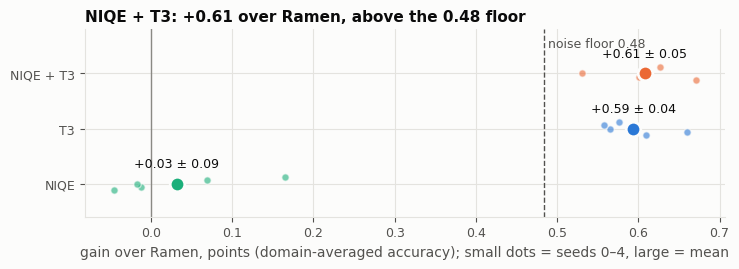

In [7]:
fig = plots.seed_gains(per_seed, FLOOR)

### Does NIQE add on top of T3? (paired, same stream)

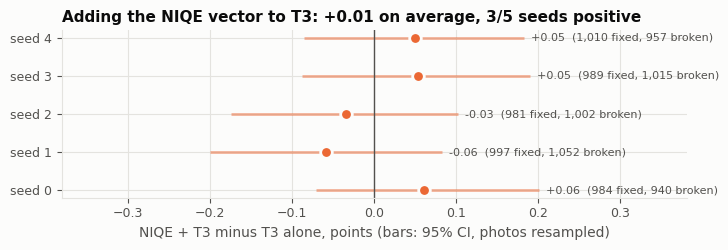

In [8]:
fig = plots.stack_vs_t3(per_seed)

### Per domain

In [9]:
corr[corr.run != 'Ramen'].groupby(['domain', 'run'])['gain vs Ramen'].mean().unstack().round(2)

run,NIQE,NIQE + T3,T3
domain,,,
adversarial,0.12,1.41,1.37
rendition,-0.01,0.08,0.06
sketch,-0.01,0.33,0.36


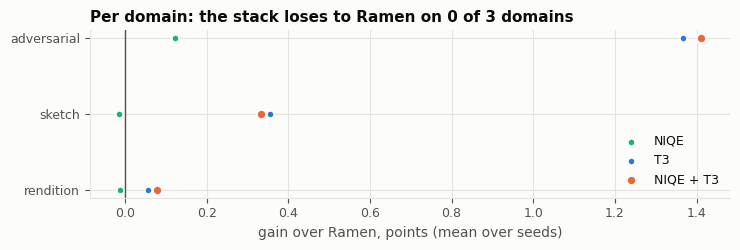

In [10]:
fig = plots.per_corruption(corr.rename(columns={'domain': 'corruption'}))

## 5. Mechanism: same-domain share of the retrieved support

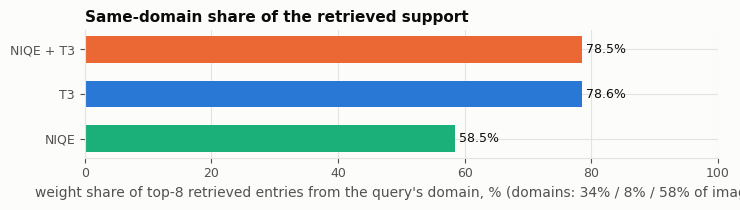

In [11]:
fig = plots.same_corruption(summary)

## 6. Interpretation

**What the numbers say**

- **The primary claim passes, but only because of T3.** NIQE + T3 gains **+0.61 ± 0.05** over Ramen (5/5 seeds positive, every seed's CI excludes 0, smallest gain +0.53 > floor 0.48). T3 alone gives +0.59 ± 0.04 on the same streams.
- **The secondary claim fails.** The stack minus T3 is **+0.01 ± 0.06**, positive on 3 of 5 seeds, and every seed's 95% CI includes 0 (−0.20 to +0.20 at the extremes). Per seed, about 990 images are fixed and about 990 broken relative to T3, out of 88,389: the NIQE term moves predictions but with no net effect.
- **NIQE alone does nothing here:** **+0.03 ± 0.09**, 2 of 5 seeds positive, every CI includes 0 (seed 4 touches it at 0.00).
- This is the outcome written down in advance as the alternative: NIQE alone ≈ 0 and the stack ≈ T3. On ImageNet-C the same settings gave NIQE alone +0.26 ± 0.04 and stack vs T3 +0.25 ± 0.05.

**Per domain (mean over seeds)**

- Adversarial: T3 +1.37, stack +1.41, NIQE alone +0.12. Rendition: +0.06 / +0.08 / −0.01. Sketch: +0.36 / +0.33 / −0.01.
- No domain shows a NIQE contribution beyond seed noise.

**Why, as far as the logs go**

- **Measured:** the same-domain share of the top-8 retrieved weight is already 78.6% under T3 and stays 78.5% with NIQE added. NIQE alone reaches 58.5%. Unlike on ImageNet-C (T3 59.0% → stack 62.5%), NIQE does not change *where* the support comes from on top of T3.
- **Hypothesis, not measured:** these domains differ in content and style (renditions, sketches, hard natural photos), not in pixel-level distortion, so NIQE's scene statistics carry little domain information beyond CLIP's own features. Also, T3 alone already concentrates the support in the query's domain here. Ramen's own same-domain share on this stream was not logged, so how much room NIQE alone had is not known.
- The flat-sketch concern is ruled out as the cause: the NIQE vector is undefined on only 0.4% of sketch images (smoke subset).

**What this means for the method**

- The ImageNet-C result (+0.87, every seed above the floor) stands, but **NIQE matching is a corruption-specific add-on, not a general improvement**. The general, held-out component is T3: +0.62 ImageNet-C, +0.59 R/A/Sketch, +0.24 DomainNet.
- Claim to write: "NIQE-vector support matching adds +0.25 on top of T3 when the test shift is a low-level image corruption (ImageNet-C), and nothing on rendition, sketch or adversarial shift."

**Caveats**

- One held-out dataset. DomainNet (style domains, β = 5) was not run. These results predict a null there, but the replay would need extending to β > 0 first.
- T = 3 was already tested on this stream, so only λ and the stack are held-out here.

**Next step**

- The natural place where NIQE *should* help is another corruption benchmark. CIFAR-100-C is the candidate, testing NIQE alone, because T3 hurts there (−0.15). But NIQE on 32 px images upsampled to 224 mostly measures the upsampling, so a null there would be uninformative.
- Otherwise, stop investing in NIQE as a domain descriptor and report it as corruption-specific.


## Glossary

| Term | Meaning |
|---|---|
| Ramen | Baseline test-time adaptation: per-class memory of entropy gradients, one SignSGD step per image from retrieved entries, then reset. |
| T3 | RamenActive with `active_set: prob`, temperature 3: class queues weighted by the query's zero-shot probabilities instead of equally. |
| NIQE vector | The 36 natural-scene-statistics features behind the NIQE quality score (block mean); used as a descriptor of the image's low-level statistics. |
| Undefined NIQE vector | Every 96 px block of the image is flat, so a feature cannot be fitted; RamenNSS then uses the stream mean. |
| Held-out | The settings (λ = 0.1, T = 3) were fixed before this data was used for them. T = 3 itself was already tested here. |
| Same-domain share | Weight share of the 8 highest-weighted retrieved entries whose domain equals the query's. Domains are 34% / 8% / 58% of the stream. |
| Noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4. |
| Fixed / broken vs T3 | Images T3 gets wrong and the stack gets right / T3 right and the stack wrong. |
| Image-level CI | Poisson bootstrap over images (R/A/Sketch share no photos). |